In [1]:

# !pip install  dataml-0.1.0-py3-none-any.whl
# !pip install graphviz

In [2]:
import matplotlib.pyplot as plt
import lightgbm as lgb
import pickle
import os
# from data_analysis_example.init_model_ml1 import mlModel
%matplotlib inline


In [3]:

model_dir = './models'
model_type = 'lgb'

In [4]:
best_model = pickle.load(open(os.path.join(model_dir,model_type+'_model.pickle'),'rb'))
best_model

LGBMClassifier(colsample_bytree=0.53, learning_rate=0.05, max_depth=7,
               min_child_samples=313, min_child_weight=0.01, n_estimators=200,
               num_leaves=48, random_state=42, reg_alpha=1, reg_lambda=2,
               scale_pos_weight=1.0, subsample=0.8)

In [5]:
model_dump = best_model.booster_.dump_model()
first_tree = model_dump['tree_info'][0]
first_tree

{'tree_index': 0,
 'num_leaves': 48,
 'num_cat': 0,
 'shrinkage': 1,
 'tree_structure': {'split_index': 0,
  'split_feature': 71,
  'split_gain': 25603,
  'threshold': 0.36076532964499775,
  'decision_type': '<=',
  'default_left': True,
  'missing_type': 'None',
  'internal_value': 0,
  'internal_weight': 0,
  'internal_count': 552807,
  'left_child': {'split_index': 2,
   'split_feature': 71,
   'split_gain': 3240.419921875,
   'threshold': 0.20378054402950674,
   'decision_type': '<=',
   'default_left': True,
   'missing_type': 'None',
   'internal_value': -0.499737,
   'internal_weight': 47482.1,
   'internal_count': 296764,
   'left_child': {'split_index': 10,
    'split_feature': 71,
    'split_gain': 471.14898681640625,
    'threshold': 0.11871830336560628,
    'decision_type': '<=',
    'default_left': True,
    'missing_type': 'None',
    'internal_value': -0.782086,
    'internal_weight': 21900.6,
    'internal_count': 136879,
    'left_child': {'split_index': 46,
     'spli

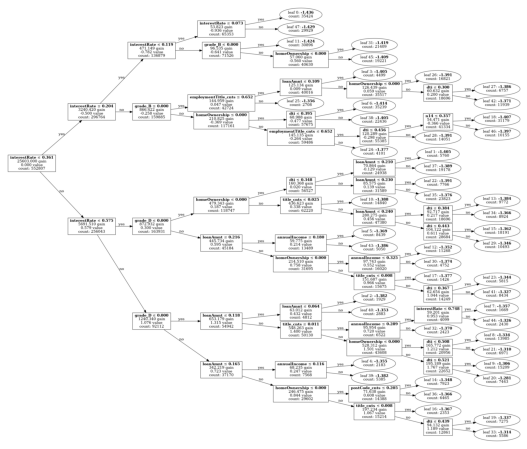

In [6]:
# ax = lgb.plot_tree(best_model, tree_index=0, figsize=(20, 8), show_info=['split_gain', 'internal_value', 'internal_count', 'leaf_count'])
# plt.show()

<Figure size 30000x18000 with 0 Axes>

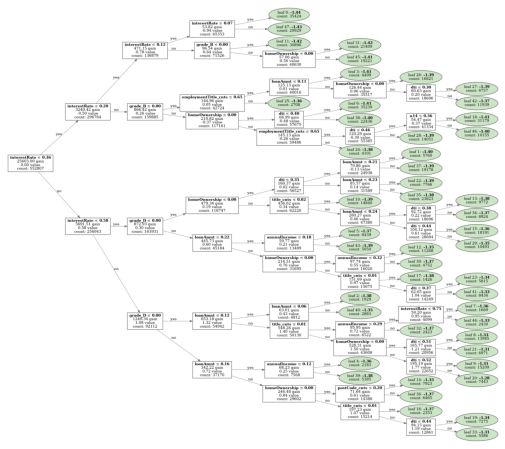

In [15]:
# 定义颜色
color_dict = {
    'split': '#488f31',  # 决策节点的颜色
    'leaf': '#ff6f61'    # 叶子节点的颜色
}

plt.figure(figsize=(50, 30), dpi=600)
# 可视化第一颗树
ax = lgb.plot_tree(best_model, tree_index=0, figsize=(20, 8), show_info=['split_gain', 'internal_value', 'internal_count', 'leaf_count'],
                   precision=2, graph_attr={'size': '50,30'}, node_attr={'style': 'filled', 'fillcolor': '#cde5c7'},
                   edge_attr={'color': '#707070'})
plt.show()

In [7]:
graph_data = lgb.create_tree_digraph(best_model, tree_index=0, name='Tree 0')
graph_data.render(view=True)

'Tree 0.gv.pdf'

Error: no "view" rule for type "application/pdf" passed its test case
       (for more information, add "--debug=1" on the command line)
/usr/bin/xdg-open: 869: www-browser: not found
/usr/bin/xdg-open: 869: links2: not found
/usr/bin/xdg-open: 869: elinks: not found
/usr/bin/xdg-open: 869: links: not found


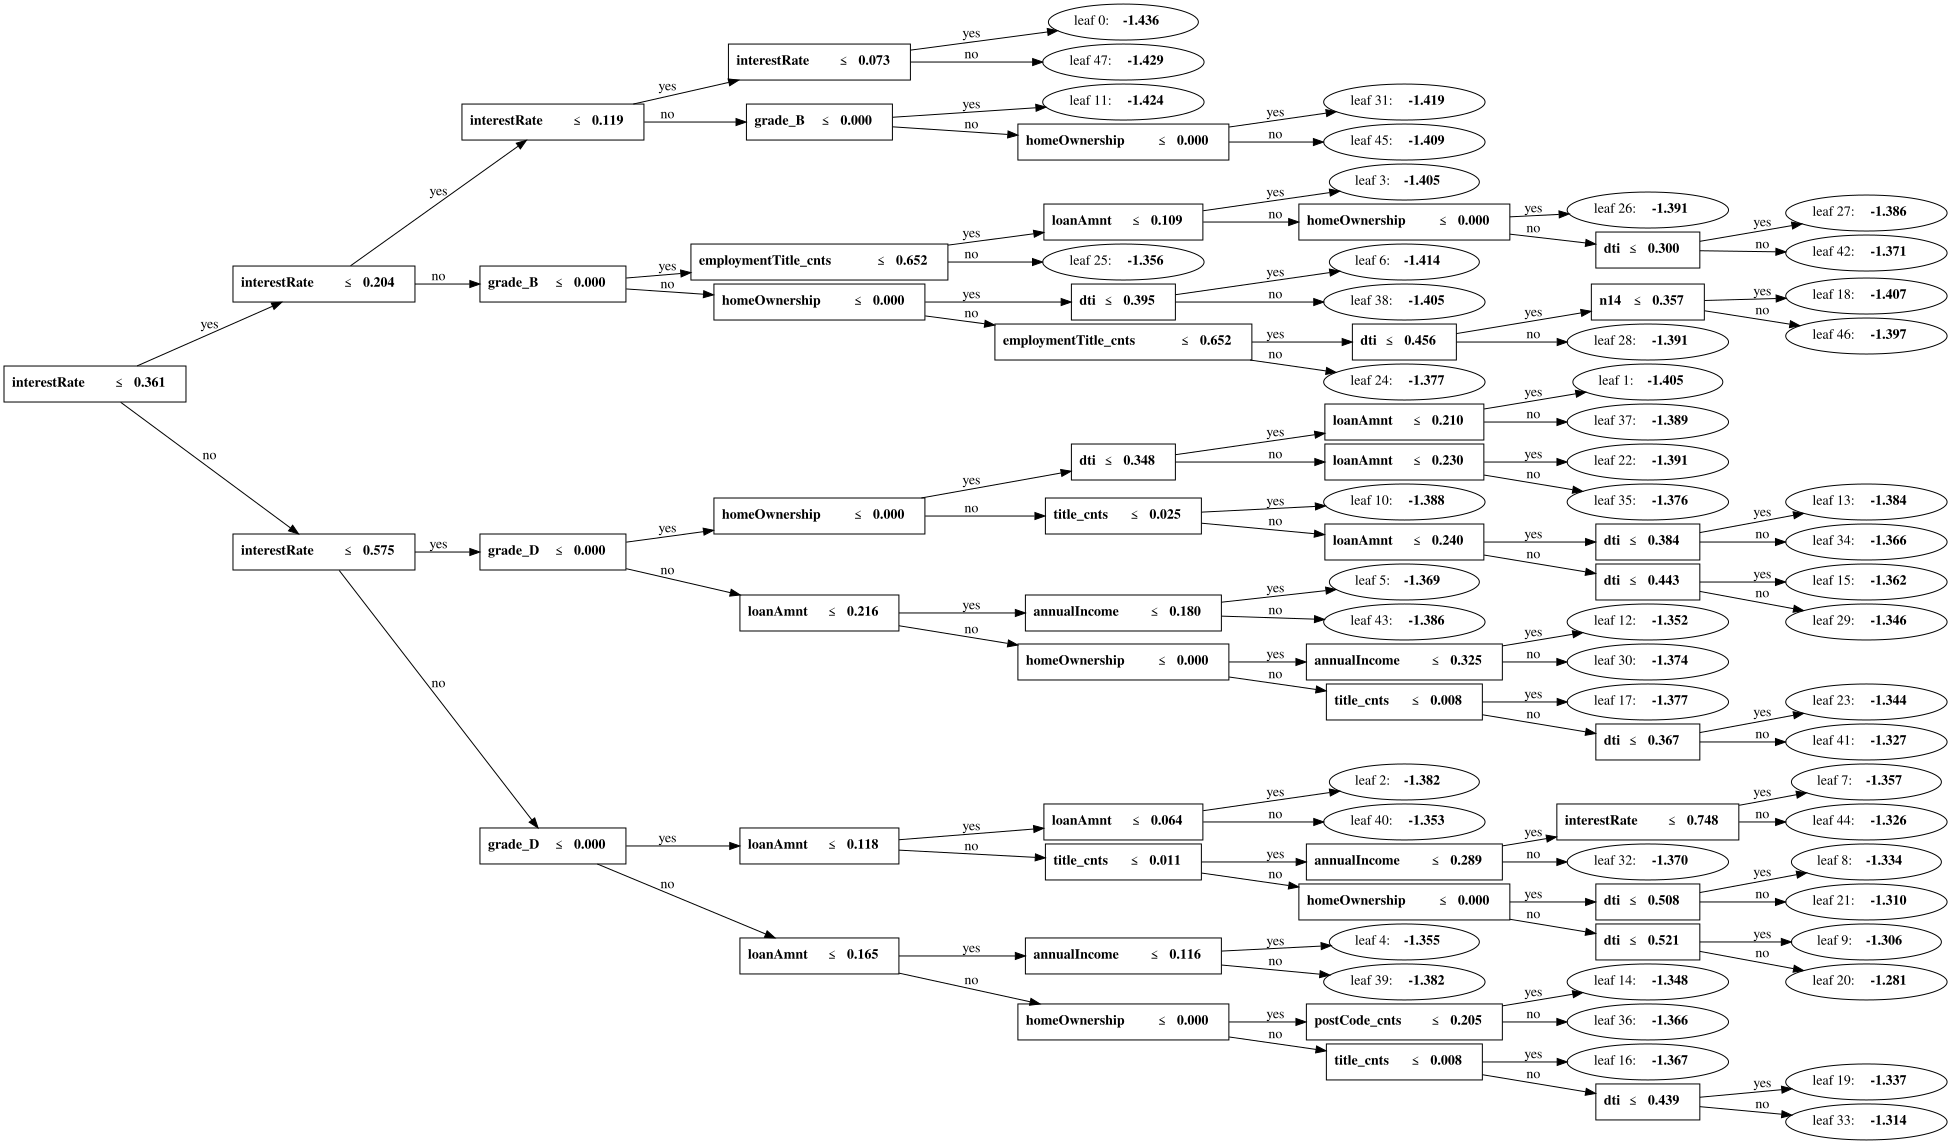

/usr/bin/xdg-open: 869: lynx: not found
/usr/bin/xdg-open: 869: w3m: not found
xdg-open: no method available for opening 'Tree 0.gv.pdf'


In [8]:
graph_data